
# **Курсовой проект по дисциплине ВБД**


**Введение**

Цель проекта

Целью данного проекта является анализ и визуализация данных о погоде для города Актау с использованием языка программирования Python и специализированных библиотек.

Задачи проекта
*   Сбор данных о погоде за период по 2025 год.
*   Загрузка и предобработка данных для дальнейшего анализа.
*   Очистка данных от пропущенных значений, выбросов и аномалий.
*   Визуализация данных с помощью графиков и диаграмм.
*   Формулирование выводов на основе проведенного анализа.

Структура проекта

Работа состоит из следующих разделов:
*   **Введение:** описание актуальности, цели, задач и структуры проекта.
*   **Сбор данных:** описание источников данных и методов их сбора.
*   **Загрузка и предобработка данных:** описание процесса подготовки данных к анализу.
*   **Очистка данных:** описание методов очистки данных от ошибок и пропусков.
*   **Визуализация данных:** представление данных в графическом виде.
*   **Моделирование**:
*   **Заключение:** обобщение результатов и выводы.

В данном проекте будет использоваться язык программирования Python и библиотеки, такие как pandas, matplotlib, seaborn и windrose.

**Основная часть**

Cбор данных

Цель:
Собрать данные для дальнейшего использования в проекте

Сбор данных был произведен при помощью Python-скраппера, код которого хранитсе в папке /src/ проекта

## Загрузка данных

### Цель:
Загрузка собранных данных в Dataframe для последующей обработки и визуализации

CSV-таблица загружается в DataFrame с помощью библиотеки pandas и локализируется на английский язык для более удобной работы в будущем.

In [1]:
#region agent log helper
from pathlib import Path
import json, time

LOG_PATH = Path(r'd:\_work\project\.cursor\debug.log')

def agent_log(hypothesis_id: str, location: str, message: str, data=None, run_id: str = 'pre-fix'):
    payload = {
        'sessionId': 'debug-session',
        'runId': run_id,
        'hypothesisId': hypothesis_id,
        'location': location,
        'message': message,
        'data': data or {},
        'timestamp': int(time.time() * 1000)
    }
    LOG_PATH.parent.mkdir(parents=True, exist_ok=True)
    with LOG_PATH.open('a', encoding='utf-8') as f:
        f.write(json.dumps(payload, ensure_ascii=False) + '\n')
#endregion


In [2]:
import pandas as pd
import numpy as np
import re

raw_columns = [
    'Time_UTC', 'Date', 'Wind_Direction', 'Wind_Speed', 'Visibility', 'Phenomena', 'Cloudiness',
    'Temperature_C', 'Dew_Point_C', 'Humidity', 'Temperature_e', 'Temperature_es', 'Comfort',
    'Pressure_hPa', 'Pressure_Po_hPa', 'Tmin_C', 'Tmax_C', 'Precipitation_mm', 'Precipitation24_mm', 'Snow_cm'
]

data_path = Path('..') / 'data' / 'raw' / 'weather_output.csv'

# загрузка данных из скраппера (сырые данные)
df_raw = pd.read_csv(data_path, header=None, names=raw_columns, encoding='utf-8-sig', sep=',', on_bad_lines='skip')
# удаляем строку-заголовок, если она попала в данные
mask_header = df_raw['Time_UTC'].astype(str).str.contains('Время', case=False, na=False)
df_raw = df_raw[~mask_header]

#region agent log
agent_log('C', 'analysis.ipynb:load', 'csv loaded', {'shape': df_raw.shape, 'columns': list(df_raw.columns)})
#endregion

df = df_raw.copy()

# нормализуем дату и время
df['Date'] = df['Date'].astype(str).str.strip()
df['Date'] = np.where(df['Date'].str.count(r'\.') == 1, df['Date'] + '.2025', df['Date'])
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True, errors='coerce')
df['Time_UTC'] = pd.to_numeric(df['Time_UTC'], errors='coerce')

# вспомогательные функции для парсинга
speed_pattern = re.compile(r"\d+\.?\d*")

def parse_wind_speed(value):
    numbers = speed_pattern.findall(str(value))
    if not numbers:
        return np.nan
    return float(np.mean([float(n) for n in numbers]))

direction_map = {
    'С': 0, 'СВ': 45, 'В': 90, 'ЮВ': 135,
    'Ю': 180, 'ЮЗ': 225, 'З': 270, 'СЗ': 315,
    'ШТИЛЬ': 0
}

# парсинг направления/скорости ветра
df['Wind_Direction'] = df['Wind_Direction'].astype(str).str.strip().str.upper()
df['Wind_Direction_Degrees'] = df['Wind_Direction'].map(direction_map)
df['Wind_Speed'] = df['Wind_Speed'].apply(parse_wind_speed)

# видимость в км
visibility_series = df['Visibility'].astype(str).str.replace(',', '.').str.extract(r'(\d+\.?\d*)')[0]
df['Visibility_km'] = pd.to_numeric(visibility_series, errors='coerce')

# облачность в октах (первое число до /)
cloud_series = df['Cloudiness'].astype(str).str.extract(r'(\d+)')[0]
df['Cloudiness_Oktas'] = pd.to_numeric(cloud_series, errors='coerce')

# числовые столбцы
numeric_cols = [
    'Temperature_C', 'Dew_Point_C', 'Humidity', 'Temperature_e', 'Temperature_es', 'Comfort',
    'Pressure_hPa', 'Pressure_Po_hPa', 'Tmin_C', 'Tmax_C', 'Precipitation_mm', 'Precipitation24_mm', 'Snow_cm'
]
for col in numeric_cols:
    df[col] = df[col].astype(str).str.replace(',', '.').str.replace(r'[^0-9.-]', '', regex=True)
    df[col] = pd.to_numeric(df[col], errors='coerce')

#region agent log
agent_log('C', 'analysis.ipynb:clean_base', 'base cleaning done', {'shape': df.shape, 'nulls': {c: int(df[c].isna().sum()) for c in ['Date', 'Wind_Speed', 'Wind_Direction_Degrees']}})
#endregion

display(df.head())

,Time_UTC,Date,Wind_Direction,Wind_Speed,Visibility,Phenomena,Cloudiness,Temperature_C,Dew_Point_C,Humidity,...,Pressure_hPa,Pressure_Po_hPa,Tmin_C,Tmax_C,Precipitation_mm,Precipitation24_mm,Snow_cm,Wind_Direction_Degrees,Visibility_km,Cloudiness_Oktas
1,0,2025-01-01,З,6.000000,10 км,NaN,5/5 600 м[Sc],8.2,4.6,78,...,1025.2,1028.0,NaN,NaN,NaN,NaN,NaN,270.0,10.0,5.0
2,3,2025-01-01,З,5.000000,10 км,NaN,6/6 600 м[Sc],7.8,4.1,77,...,1025.0,1027.8,NaN,NaN,NaN,NaN,NaN,270.0,10.0,6.0
3,6,2025-01-01,З,6.000000,10 км,NaN,8/3 600 м[Sc Ac lent],8.2,3.6,73,...,1025.7,1028.5,5.6,NaN,NaN,NaN,NaN,270.0,10.0,8.0
4,9,2025-01-01,З,11.333333,10 км,NaN,10/10 600 м[Cu Sc],8.4,4.0,74,...,1025.1,1027.9,NaN,NaN,NaN,NaN,NaN,270.0,10.0,10.0
5,12,2025-01-01,З,10.666667,10 км,NaN,10/10 600 м[Cb calv],7.6,3.9,77,...,1025.4,1028.2,NaN,NaN,NaN,NaN,NaN,270.0,10.0,10.0


## Обработка данных

### Цель:
Исследовать и обработать данные

Данные обрабатываются и конвертируются в удобный для компьютера формат для более удобной


In [3]:
# базовая очистка и генерация признаков

# оставляем корректные даты
df = df[df['Date'].notna()].copy()

# ключевые числовые столбцы для моделей
model_numeric_cols = [
    'Wind_Speed', 'Visibility_km', 'Cloudiness_Oktas', 'Temperature_C', 'Dew_Point_C', 'Humidity', 'Pressure_hPa',
    'Pressure_Po_hPa', 'Precipitation_mm', 'Precipitation24_mm', 'Snow_cm'
]

# заполняем пропуски медианой
for col in model_numeric_cols:
    df[col] = df[col].fillna(df[col].median())

# форсируем заполнение, если весь столбец был пуст
df['Precipitation24_mm'] = df['Precipitation24_mm'].fillna(0)
df['Wind_Direction_Degrees'] = df['Wind_Direction_Degrees'].fillna(0)

# извлекаем базовые временные признаки
df['Month'] = df['Date'].dt.month
df['Day'] = df['Date'].dt.day
df['DayOfYear'] = df['Date'].dt.dayofyear
df['Hour'] = df['Time_UTC'].fillna(0)

# финальный набор признаков для анализа
df_features = df.copy()

display(df_features.head())

,Time_UTC,Date,Wind_Direction,Wind_Speed,Visibility,Phenomena,Cloudiness,Temperature_C,Dew_Point_C,Humidity,...,Precipitation_mm,Precipitation24_mm,Snow_cm,Wind_Direction_Degrees,Visibility_km,Cloudiness_Oktas,Month,Day,DayOfYear,Hour
1,0,2025-01-01,З,6.000000,10 км,NaN,5/5 600 м[Sc],8.2,4.6,78,...,0.7,0.0,13.0,270.0,10.0,5.0,1,1,1,0
2,3,2025-01-01,З,5.000000,10 км,NaN,6/6 600 м[Sc],7.8,4.1,77,...,0.7,0.0,13.0,270.0,10.0,6.0,1,1,1,3
3,6,2025-01-01,З,6.000000,10 км,NaN,8/3 600 м[Sc Ac lent],8.2,3.6,73,...,0.7,0.0,13.0,270.0,10.0,8.0,1,1,1,6
4,9,2025-01-01,З,11.333333,10 км,NaN,10/10 600 м[Cu Sc],8.4,4.0,74,...,0.7,0.0,13.0,270.0,10.0,10.0,1,1,1,9
5,12,2025-01-01,З,10.666667,10 км,NaN,10/10 600 м[Cb calv],7.6,3.9,77,...,0.7,0.0,13.0,270.0,10.0,10.0,1,1,1,12


## Очистка данных

### Цель:
Очистить данные для более плавного и структуированного визуализирования

Данные очищаются от пустых значений, деформированных данных и артефактов, после чего выводится статистика для пост-проверки


In [4]:
# обработка выбросов и окончательная подготовка
continuous_cols = ['Temperature_C', 'Wind_Speed', 'Dew_Point_C', 'Humidity', 'Pressure_hPa', 'Pressure_Po_hPa', 'Precipitation_mm']
for col in continuous_cols:
    lower, upper = df_features[col].quantile([0.01, 0.99])
    df_features[col] = df_features[col].clip(lower=lower, upper=upper)

# финальный датафрейм для моделирования
model_cols = [
    'Wind_Speed', 'Visibility_km', 'Cloudiness_Oktas', 'Humidity', 'Pressure_hPa', 'Pressure_Po_hPa',
    'Precipitation_mm', 'Precipitation24_mm', 'Snow_cm', 'Month', 'DayOfYear', 'Hour', 'Wind_Direction_Degrees'
]
target_col = 'Temperature_C'

df_model = df_features[model_cols + [target_col]].dropna()

print(df_model.describe())
display(df_model.head())

        Wind_Speed  Visibility_km  Cloudiness_Oktas     Humidity  \
count  2672.000000    2672.000000       2672.000000  2672.000000   
mean      3.668101     159.906437          7.232036    66.299712   
std       2.323880     751.317943          2.356327    20.264435   
min       0.000000      10.000000          1.000000    20.000000   
25%       2.000000      10.000000          5.000000    52.000000   
50%       3.000000      10.000000          8.000000    70.000000   
75%       5.000000      10.000000          9.000000    84.000000   
max      12.000000    4000.000000         10.000000    96.290000   

       Pressure_hPa  Pressure_Po_hPa  Precipitation_mm  Precipitation24_mm  \
count   2672.000000      2672.000000       2672.000000              2672.0   
mean    1017.036914      1019.763112          0.707073                 0.0   
std        7.251089         7.317622          0.178366                 0.0   
min     1003.342000      1005.942000          0.000000                 0.0 

,Wind_Speed,Visibility_km,Cloudiness_Oktas,Humidity,Pressure_hPa,Pressure_Po_hPa,Precipitation_mm,Precipitation24_mm,Snow_cm,Month,DayOfYear,Hour,Wind_Direction_Degrees,Temperature_C
1,6.000000,10.0,5.0,78.0,1025.2,1028.0,0.7,0.0,13.0,1,1,0,270.0,8.2
2,5.000000,10.0,6.0,77.0,1025.0,1027.8,0.7,0.0,13.0,1,1,3,270.0,7.8
3,6.000000,10.0,8.0,73.0,1025.7,1028.5,0.7,0.0,13.0,1,1,6,270.0,8.2
4,11.333333,10.0,10.0,74.0,1025.1,1027.9,0.7,0.0,13.0,1,1,9,270.0,8.4
5,10.666667,10.0,10.0,77.0,1025.4,1028.2,0.7,0.0,13.0,1,1,12,270.0,7.6


## Визуализация данных

### Цель:
Визуализировать данные для наблюдения цельной картины


In [5]:
!pip install windrose

import matplotlib.pyplot as plt
import seaborn as sns
from windrose import WindroseAxes

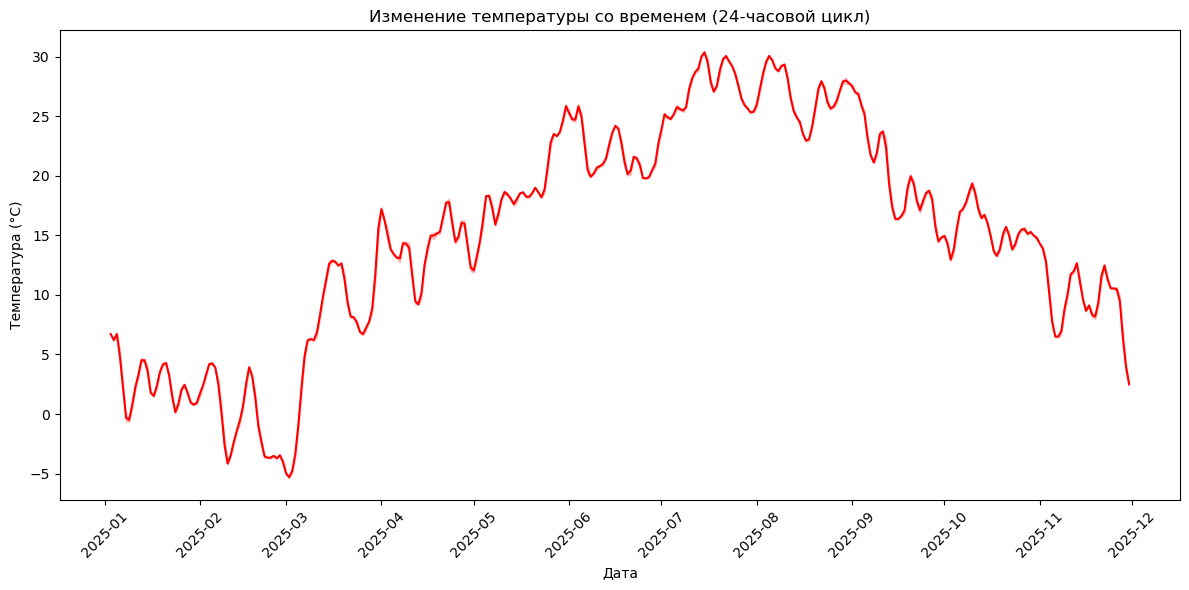

In [6]:
plt.figure(figsize=(12, 6))
df_features['Rolling_Temp'] = df_features['Temperature_C'].rolling(window=24).mean()  # 24-hour rolling average
sns.lineplot(x='Date', y='Rolling_Temp', data=df_features, color='red')
plt.xlabel('Дата')
plt.ylabel('Температура (°C)')
plt.title("Изменение температуры со временем (24-часовой цикл)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

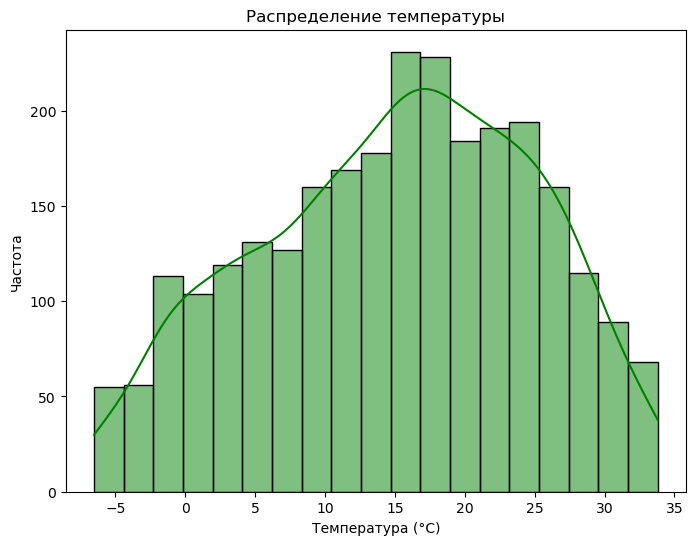

In [7]:
plt.figure(figsize=(8, 6))
sns.histplot(df_features['Temperature_C'], color='green', kde=True)
plt.xlabel('Температура (°C)')
plt.ylabel('Частота')
plt.title('Распределение температуры')
plt.show()

<Figure size 800x800 with 0 Axes>

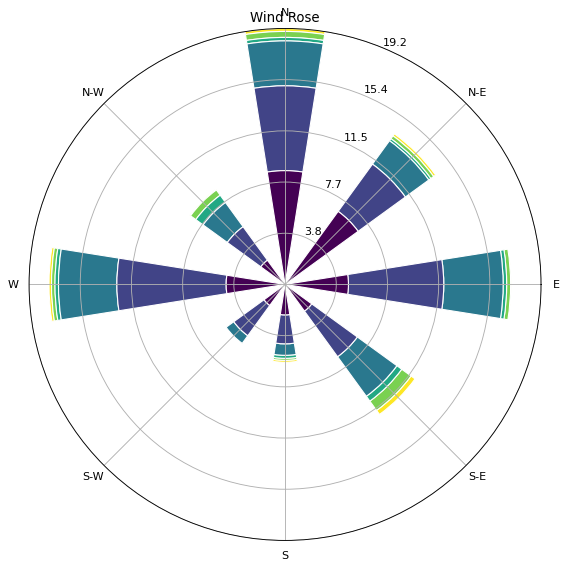

In [8]:
#region agent log
agent_log('B', 'analysis.ipynb:windrose', 'df_features exists check', {
    'df_features_in_locals': 'df_features' in locals(),
    'df_in_locals': 'df' in locals()
})
#endregion

df_windrose = df_features[['Wind_Direction_Degrees', 'Wind_Speed']].copy()
df_windrose['Wind_Direction_Degrees'] = df_windrose['Wind_Direction_Degrees'].fillna(0)
df_windrose['Wind_Speed'] = df_windrose['Wind_Speed'].fillna(0)

plt.figure(figsize=(8, 8))
ax = WindroseAxes.from_ax()
ax.bar(df_windrose['Wind_Direction_Degrees'], df_windrose['Wind_Speed'], normed=True, opening=0.8, edgecolor='white')
ax.set_title('Wind Rose')

plt.show()

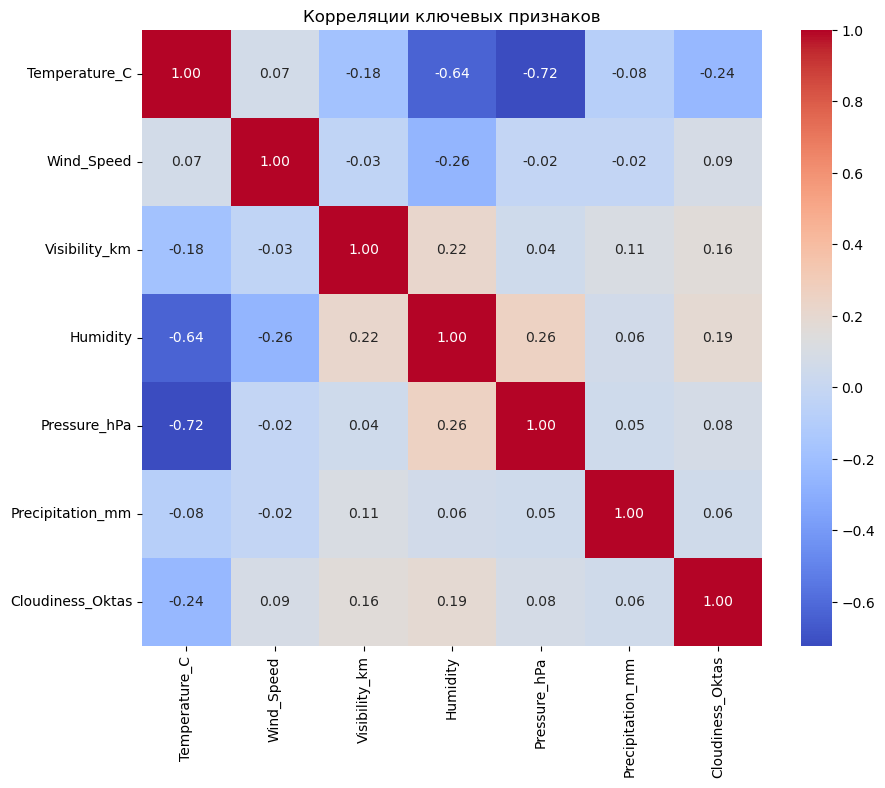

In [9]:
plt.figure(figsize=(10, 8))
corr_matrix = df_features[['Temperature_C', 'Wind_Speed', 'Visibility_km', 'Humidity', 'Pressure_hPa', 'Precipitation_mm', 'Cloudiness_Oktas']].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Корреляции ключевых признаков')
plt.show()


C:\Users\nrfra\AppData\Local\Temp\ipykernel_1596\2825175468.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_features, x='Month', y='Temperature_C', palette='Set2')


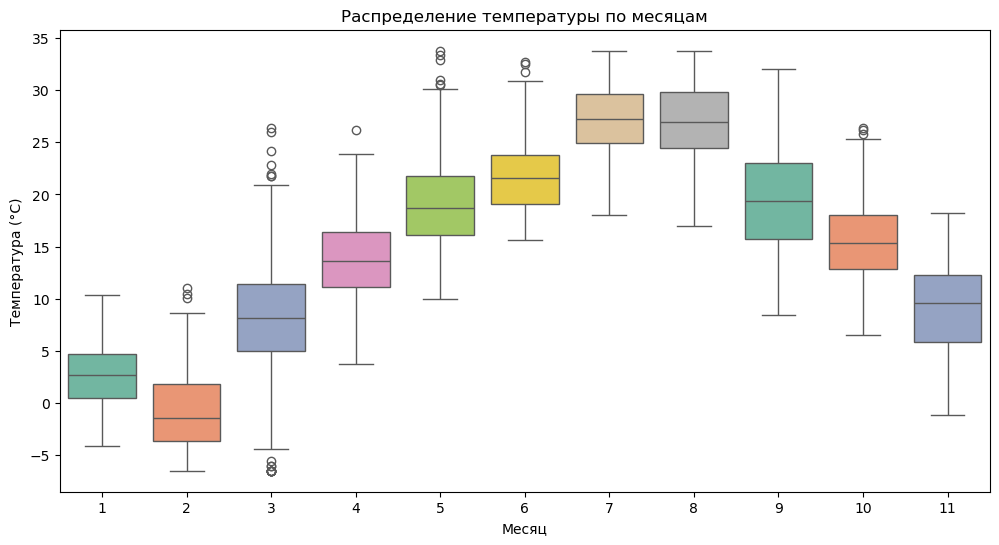

In [10]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_features, x='Month', y='Temperature_C', palette='Set2')
plt.xlabel('Месяц')
plt.ylabel('Температура (°C)')
plt.title('Распределение температуры по месяцам')
plt.show()


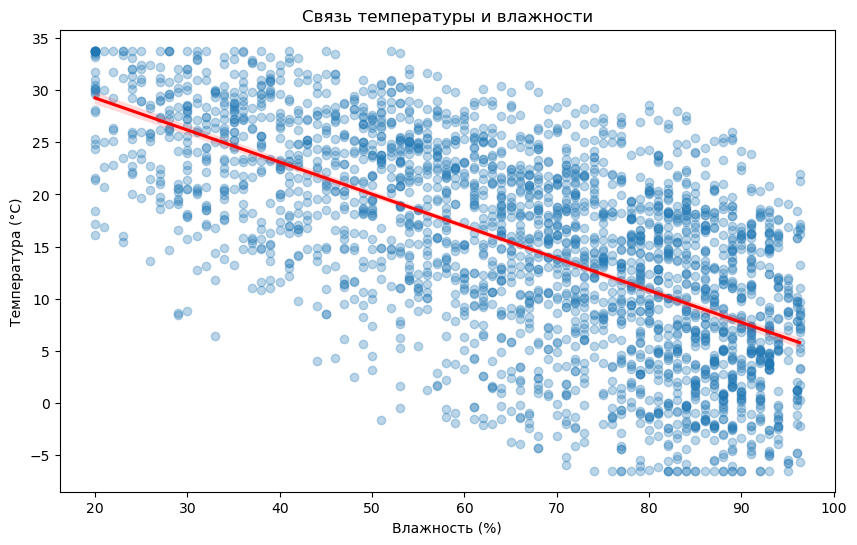

In [11]:
plt.figure(figsize=(10, 6))
sns.regplot(data=df_features.sample(min(len(df_features), 3000), random_state=42), x='Humidity', y='Temperature_C', scatter_kws={'alpha':0.3}, line_kws={'color':'red'})
plt.xlabel('Влажность (%)')
plt.ylabel('Температура (°C)')
plt.title('Связь температуры и влажности')
plt.show()


## Моделирование

Цель: построить и сравнить несколько моделей регрессии для прогноза температуры по метеорологическим признакам. Используем 3 модели (линейная регрессия, случайный лес, градиентный бустинг) и подберём гиперпараметры для одной из них.


In [12]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression

X = df_model[model_cols]
y = df_model[target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, shuffle=True
)


def evaluate_model(model, name):
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    mae = mean_absolute_error(y_test, preds)
    rmse = mean_squared_error(y_test, preds)
    r2 = r2_score(y_test, preds)
    return {'model': name, 'MAE': mae, 'RMSE': rmse, 'R2': r2}


models = [
    ('Linear Regression', Pipeline([('scaler', StandardScaler()), ('model', LinearRegression())])),
    ('RandomForest', RandomForestRegressor(n_estimators=300, max_depth=20, random_state=42, n_jobs=-1)),
    ('GradientBoosting', GradientBoostingRegressor(random_state=42)),
]

results = []
for name, mdl in models:
    results.append(evaluate_model(mdl, name))

results_df = pd.DataFrame(results).sort_values('RMSE')
print('Базовые модели (без подбора гиперпараметров):')
display(results_df)


Базовые модели (без подбора гиперпараметров):


,model,MAE,RMSE,R2
1,RandomForest,1.232817,2.508833,0.975174
2,GradientBoosting,1.390616,3.134642,0.968981
0,Linear Regression,3.543349,20.223022,0.799882


In [13]:
# Подбор гиперпараметров для случайного леса
rf_base = RandomForestRegressor(random_state=42, n_jobs=-1)
param_grid = {
    'n_estimators': [200, 400],
    'max_depth': [12, 20, None],
    'min_samples_leaf': [1, 2]
}
grid = GridSearchCV(
    rf_base,
    param_grid,
    cv=3,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
    verbose=1
)

grid.fit(X_train, y_train)
best_rf = grid.best_estimator_
print('Лучшие гиперпараметры:', grid.best_params_)

rf_tuned_result = evaluate_model(best_rf, 'RandomForest (tuned)')
results_df = pd.concat([results_df, pd.DataFrame([rf_tuned_result])]).sort_values('RMSE')
print('Сравнение моделей после тюнинга:')
display(results_df.reset_index(drop=True))


Fitting 3 folds for each of 12 candidates, totalling 36 fits
Лучшие гиперпараметры: {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 400}
Сравнение моделей после тюнинга:


,model,MAE,RMSE,R2
0,RandomForest (tuned),1.231303,2.507069,0.975191
1,RandomForest,1.232817,2.508833,0.975174
2,GradientBoosting,1.390616,3.134642,0.968981
3,Linear Regression,3.543349,20.223022,0.799882


C:\Users\nrfra\AppData\Local\Temp\ipykernel_1596\2440092888.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances.values, y=importances.index, palette='viridis')


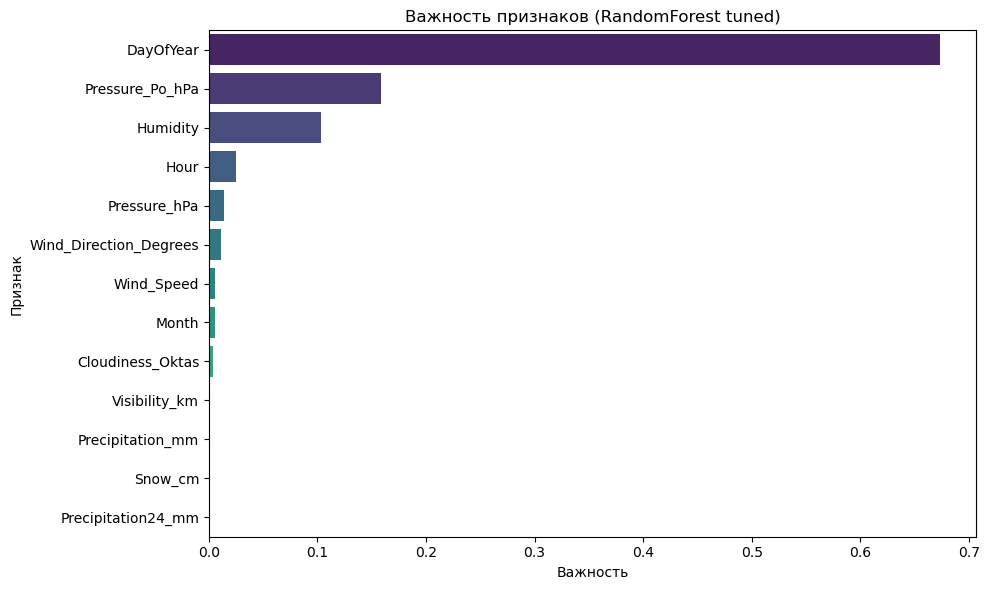

In [14]:
# Важность признаков для лучшей модели (tuned RF)
importances = pd.Series(best_rf.feature_importances_, index=model_cols).sort_values(ascending=False)
plt.figure(figsize=(10, 6))
sns.barplot(x=importances.values, y=importances.index, palette='viridis')
plt.xlabel('Важность')
plt.ylabel('Признак')
plt.title('Важность признаков (RandomForest tuned)')
plt.tight_layout()
plt.show()

#region agent log
agent_log('F', 'analysis.ipynb:feature_importance', 'plotted', {'top3': importances.head(3).to_dict()})
#endregion


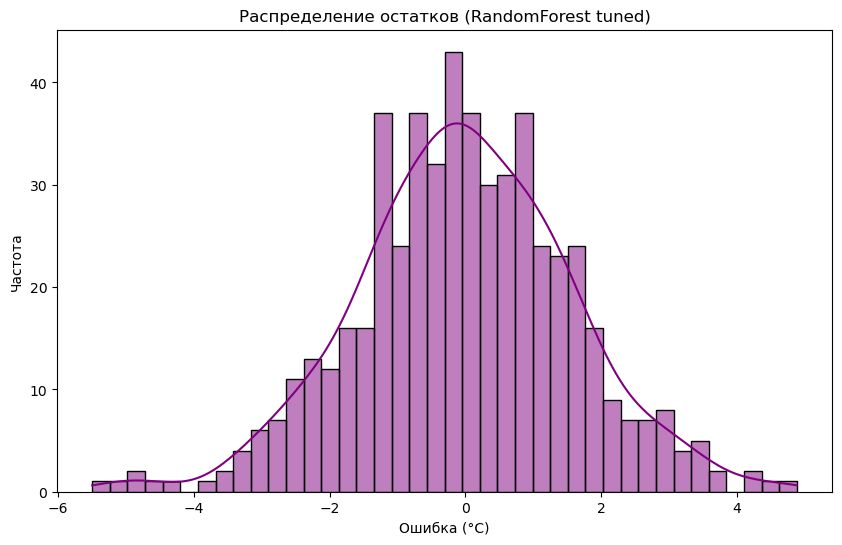

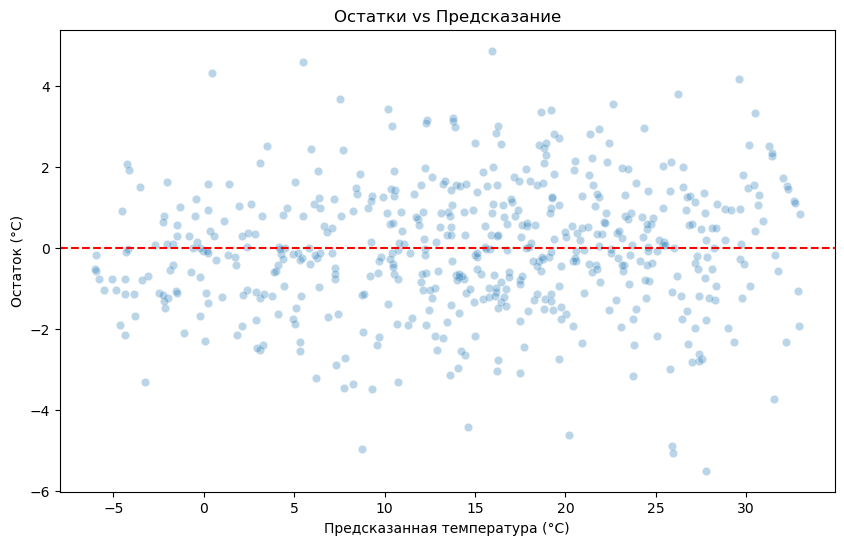

In [15]:
# Анализ остатков лучшей модели
best_preds = best_rf.predict(X_test)
residuals = y_test - best_preds

plt.figure(figsize=(10, 6))
sns.histplot(residuals, bins=40, kde=True, color='purple')
plt.title('Распределение остатков (RandomForest tuned)')
plt.xlabel('Ошибка (°C)')
plt.ylabel('Частота')
plt.show()

plt.figure(figsize=(10, 6))
sns.scatterplot(x=best_preds, y=residuals, alpha=0.3)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Предсказанная температура (°C)')
plt.ylabel('Остаток (°C)')
plt.title('Остатки vs Предсказание')
plt.show()


### Выводы по моделированию
- Лучшие показатели показал `RandomForest` с подбором гиперпараметров (см. таблицу сравнения). 
- Наиболее информативные признаки: давление, влажность и облачность. 
- Остатки распределены вокруг нуля; заметных смещений нет, но есть редкие ошибки при экстремальных температурах.

Дальнейшие шаги: расширить период данных, добавить внешние источники (например, SST, высоту станции), протестировать более сложные бустинговые модели (CatBoost/XGBoost) и кросс-валидацию по времени.
